# Quick question

The below table shows the number of air conditioning units sold and their advertised price across a company's annual sales. Examine the data and the different variables, and then answer the question below.

In [1]:
import pandas as pd
data = pd.read_csv('./data/week_1_lesson_3.csv')

display(data)

,Month,Temperature (degrees),Advertised Cost ($),Units Sold
0,January,29,2199,98
1,February,28,2199,101
2,March,25,1859,81
3,April,21,1799,68
4,May,17,1559,34
5,June,15,1499,25
6,July,12,1499,26
7,August,12,1499,24
8,September,14,1659,41
9,October,19,1799,59


In [2]:
display(
    data.style
        .hide(axis="index")
        .format({
            "Temperature (degrees)": "{:.0f}°",
            "Advertised Cost ($)": "${:,.0f}",
            "Units Sold": "{:.0f}"
        })
        .background_gradient(subset=["Temperature (degrees)"], cmap="Oranges")
        .background_gradient(subset=["Advertised Cost ($)"], cmap="Greens")
        .background_gradient(subset=["Units Sold"], cmap="Blues")
)

Month,Temperature (degrees),Advertised Cost ($),Units Sold
January,29°,"$2,199",98
February,28°,"$2,199",101
March,25°,"$1,859",81
April,21°,"$1,799",68
May,17°,"$1,559",34
June,15°,"$1,499",25
July,12°,"$1,499",26
August,12°,"$1,499",24
September,14°,"$1,659",41
October,19°,"$1,799",59


Note: this requires installing the `dataframe_image` package. You can install it using pip:
```bash
pip install dataframe_image
```

Also, you might need to run:

```bash
pip install --upgrade requests
pip install --upgrade pip
```

To avoid the error:
`/Users/alvaro/Library/Caches/JetBrains/PyCharm2024.2/demo/PyCharmLearningProject/venv/lib/python3.12/site-packages/requests/init.py:113: RequestsDependencyWarning: urllib3 (2.8.0) or chardet (7.7.0)/charset_normalizer (3.4.1) doesn't match a supported version!
  warnings.warn(`

In [3]:
import dataframe_image as dfi

styled_data = (
    data.style
        .hide(axis="index")
        .format({
            "Temperature (degrees)": "{:.0f}°",
            "Advertised Cost ($)": "${:,.0f}",
            "Units Sold": "{:.0f}"
        })
        .background_gradient(subset=["Temperature (degrees)"], cmap="Oranges")
        .background_gradient(subset=["Advertised Cost ($)"], cmap="Greens")
        .background_gradient(subset=["Units Sold"], cmap="Blues")
)

display(styled_data)

dfi.export(
    styled_data,
    "./images/week_1/colourful_table.png",
    table_conversion="matplotlib",
    dpi=300
)

Month,Temperature (degrees),Advertised Cost ($),Units Sold
January,29°,"$2,199",98
February,28°,"$2,199",101
March,25°,"$1,859",81
April,21°,"$1,799",68
May,17°,"$1,559",34
June,15°,"$1,499",25
July,12°,"$1,499",26
August,12°,"$1,499",24
September,14°,"$1,659",41
October,19°,"$1,799",59


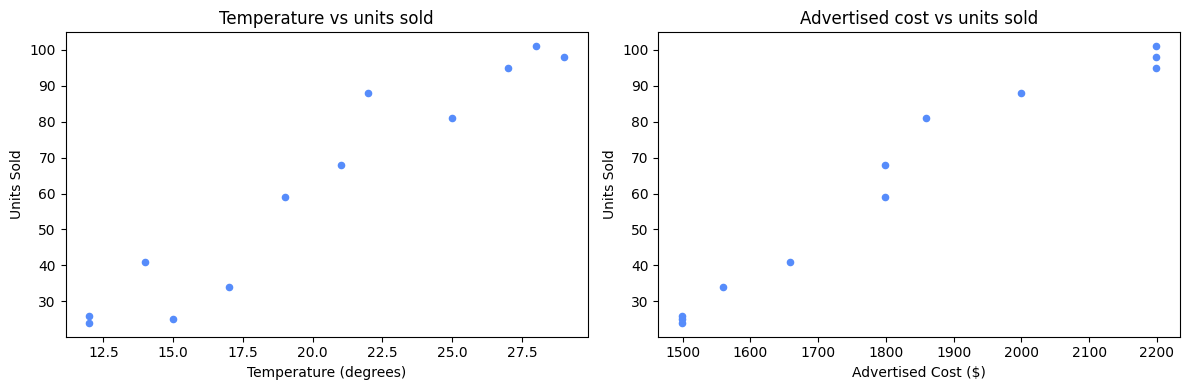

In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

data.plot.scatter(
    x="Temperature (degrees)",
    y="Units Sold",
    ax=axes[0],
    title="Temperature vs units sold"
)

data.plot.scatter(
    x="Advertised Cost ($)",
    y="Units Sold",
    ax=axes[1],
    title="Advertised cost vs units sold"
)

plt.tight_layout()
plt.show()

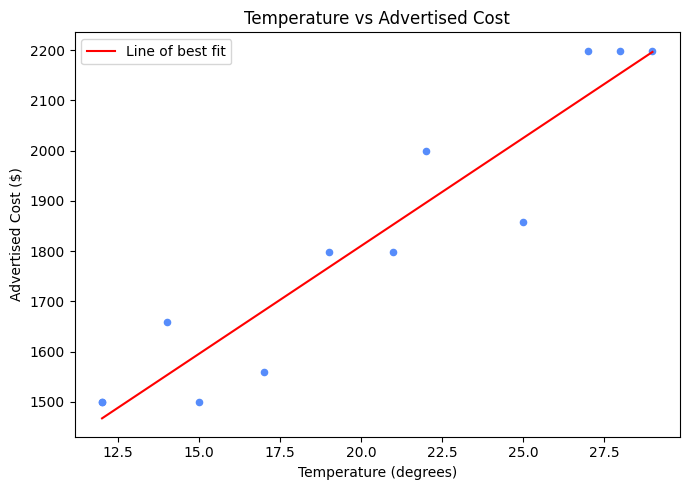

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Keep complete pairs of values
pairs = data[["Temperature (degrees)", "Advertised Cost ($)"]].dropna()
x = pairs["Temperature (degrees)"]
y = pairs["Advertised Cost ($)"]

ax = pairs.plot.scatter(
    x="Temperature (degrees)",
    y="Advertised Cost ($)",
    title="Temperature vs Advertised Cost",
    figsize=(7, 5)
)

# Calculate and plot the line of best fit
slope, intercept = np.polyfit(x, y, 1)
x_line = np.linspace(x.min(), x.max(), 100)

ax.plot(
    x_line,
    slope * x_line + intercept,
    color="red",
    label="Line of best fit"
)

ax.legend()
plt.tight_layout()
plt.savefig("./images/week_1/temperature_vs_cost.png", dpi=300, bbox_inches="tight")
plt.show()

In [6]:
correlation = data["Temperature (degrees)"].corr(
    data["Advertised Cost ($)"]
)

print(f"Correlation: {correlation:.3f}")

Correlation: 0.947


A value close to **+1** indicates a strong positive relationship: higher temperatures tend to coincide with higher advertised costs.